 Running 16-node portfolio validation...
Return file: ap_tree_node_data_深度4/ap_tree_all_nodes_returns.csv
Number of nodes specified: 16
 Reading return data...
Total periods in data: 360
Total nodes in data: 1555
Test periods: 60
 Removing 1 specified nodes not found in data.
 Nodes used for portfolio: 15

表格1：APT策略与基准组合样本外业绩表现
 APT 策略 根节点表现 (全市场等权重) 基准2 (等权-入选节点)
指标   
年化收益率 81.49% 9.54% 72.78%
年化波动率 29.66% 22.37% 29.45%
年化夏普比率 2.747 0.426 2.472
累计收益率 1,519.67% 39.61% 1,168.74%
最大回撤 -17.85% -27.03% -18.41%
Calmar比率 4.565 0.353 3.954
月度胜率 75.00% 55.00% 73.33%



 Chart saved as: portfolio_analysis_with_root.png


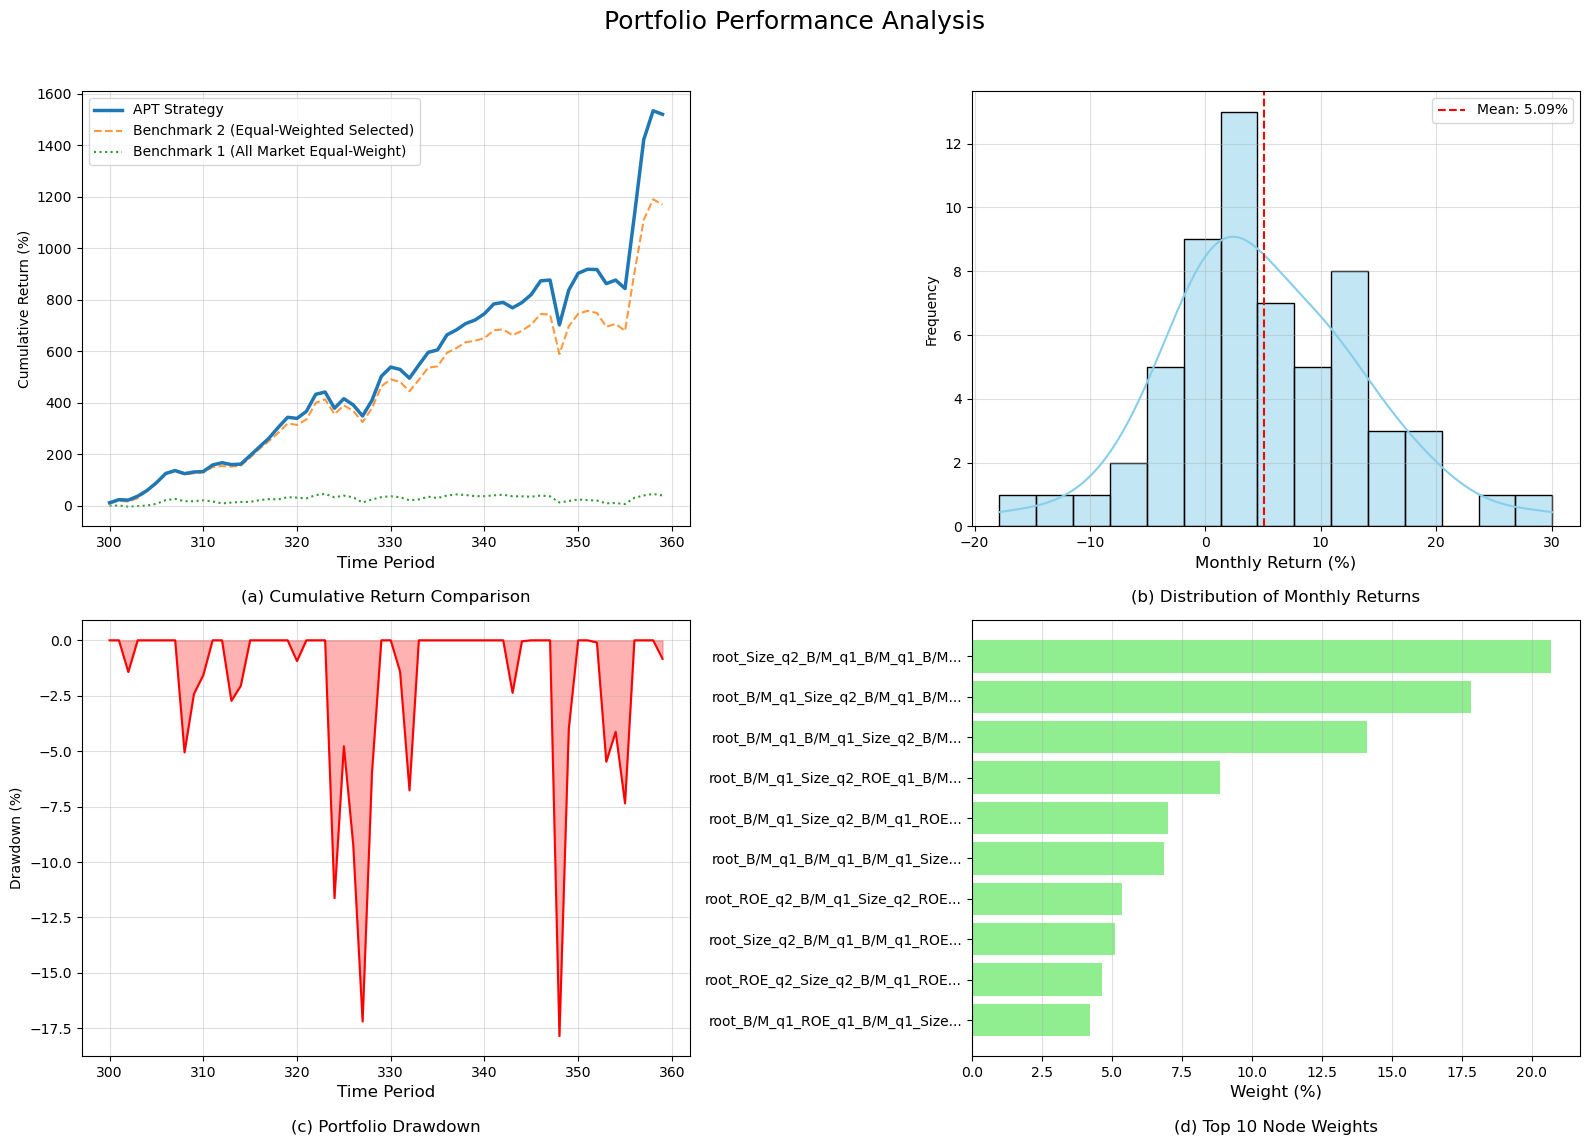


根节点表现详细指标
累计收益率: 39.61%
年化收益率: 9.54%
年化波动率: 22.37%
夏普比率: 0.426
最大回撤: -27.03%
Calmar比率: 0.353
月度胜率: 55.00%


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib import rcParams
from io import StringIO

# Berchmark 2 用到的16个节点和权重
node_weights = {
    'root_规模_q2_账面市值比_q1_账面市值比_q1_账面市值比_q1':0.200851892600014,
    'root_账面市值比_q1_规模_q2_账面市值比_q1_账面市值比_q1':0.17300246496453855,
    'root_账面市值比_q1_账面市值比_q1_规模_q2_账面市值比_q1':0.1369899192687146,
    'root_账面市值比_q1_规模_q2_净资产收益率_q1_账面市值比_q1':0.08613634407194284,
    'root_账面市值比_q1_规模_q2_账面市值比_q1_净资产收益率_q1':0.06815791342046872,
    'root_账面市值比_q1_账面市值比_q1_账面市值比_q1_规模_q2':0.06675492743788379,
    'root_净资产收益率_q2_账面市值比_q1_规模_q2_净资产收益率_q2':0.052072636029621026,
    'root_规模_q2_账面市值比_q1_账面市值比_q1_净资产收益率_q1':0.04976914588602582,
    'root_净资产收益率_q2_规模_q2_账面市值比_q1_净资产收益率_q2':0.045209218529220295,
    'root_账面市值比_q1_净资产收益率_q1_账面市值比_q1_规模_q2':0.041101144601902215,
    'root_账面市值比_q1_市账面市值比_q1_规模_q2_净资产收益率_q1':0.029256923640976373,
    'root_规模_q2_账面市值比_q1_净资产收益率_q1_账面市值比_q1':0.016500614235560308,
    'root_规模_q2_净资产收益率_q1_账面市值比_q1_账面市值比_q1':0.013833413634589358,
    'root_规模_q2_账面市值比_q1_净资产收益率_q1_净资产收益率_q1':0.007846366247767987,
    'root_账面市值比_q1_规模_q2_净资产收益率_q2_净资产收益率_q2':0.0064280154354823356,
    'root_账面市值比_q1_净资产收益率_q2_规模_q2_净资产收益率_q2':0.006089059995291786
}

# 中文到英文的翻译字典
translation_dict = {
    '规模': 'Size',
    '账面市值比': 'B/M',
    '净资产收益率': 'ROE'
}

# 根节点数据字符串
root_data_str = """date	root
Jan-20	0.0024058909487459155
Feb-20	-0.001116788
Mar-20	-0.037472915
Apr-20	0.0203560868976719
May-20	0.020901635579514823
Jun-20	0.06851908778523491
Jul-20	0.13462935964677547
Aug-20	0.03706264990689013
Sep-20	-0.070396077
Oct-20	0.0012530332800852002
Nov-20	0.02825783040468583
Dec-20	-0.034706932
Jan-21	-0.067398888
Feb-21	0.031420496054975815
Mar-21	0.021181445035460995
Apr-21	0.0015043011592741965
May-21	0.060449494881398246
Jun-21	0.029222477926587304
Jul-21	-0.005502115
Aug-21	0.06981799193942353
Sep-21	-0.015973684
Oct-21	-0.020916142
Nov-21	0.09851372531769305
Dec-21	0.03463463734115347
Jan-22	-0.091395788
Feb-22	0.04887253878802169
Mar-22	-0.047573962
Apr-22	-0.150868431
May-22	0.1042254384236453
Jun-22	0.07201306196133239
Jul-22	0.028139138623103847
Aug-22	-0.029490005
Sep-22	-0.089107313
Oct-22	0.0278747914824296
Nov-22	0.08466559609120519
Dec-22	-0.03961197
Jan-23	0.0761709934015927
Feb-23	0.03145823465211459
Mar-23	-0.016277135
Apr-23	-0.031151327
May-23	-0.000821313
Jun-23	0.02356743459726273
Jul-23	0.01678708889386475
Aug-23	-0.042903174
Sep-23	-0.000425541
Oct-23	-0.010796062
Nov-23	0.03360105277280858
Dec-23	-0.021545787
Jan-24	-0.176700914
Feb-24	0.052120336351590094
Mar-24	0.04962581262414477
Apr-24	-0.020022268
May-24	-0.014019083
Jun-24	-0.088184432
Jul-24	0.009489769520017692
Aug-24	-0.034803845
Sep-24	0.22613984900221726
Oct-24	0.06930427649667405
Nov-24	0.044516915983152286
Dec-24	-0.042217456"""

def translate_node_name(node_name, trans_dict):
    """
    将节点名称中的中文因子翻译成英文。
    """
    for cn, en in trans_dict.items():
        node_name = node_name.replace(cn, en)
    return node_name

def calculate_performance_metrics(portfolio_returns):
    """
    为给定的收益率序列计算所有需要的性能指标。
    """
    if len(portfolio_returns) == 0:
        return {
            '年化收益率': 0, '年化波动率': 0, '年化夏普比率': 0,
            '累计收益率': 0, '最大回撤': 0, 'Calmar比率': 0, '月度胜率': 0
        }

    mean_return = np.mean(portfolio_returns)
    std_return = np.std(portfolio_returns, ddof=1)

    # 年化指标
    annual_return = (1 + mean_return)**12 - 1
    annual_volatility = std_return * np.sqrt(12)
    sharpe_ratio = (annual_return / annual_volatility) if annual_volatility > 1e-8 else 0

    # 累计与回撤
    cumulative_returns = np.cumprod(1 + portfolio_returns) - 1
    total_return = cumulative_returns[-1]

    cumulative_values = np.cumprod(1 + portfolio_returns)
    peak = np.maximum.accumulate(cumulative_values)
    drawdown = (cumulative_values - peak) / peak
    max_drawdown = np.min(drawdown)

    # 其他比率
    calmar_ratio = (annual_return / abs(max_drawdown)) if abs(max_drawdown) > 1e-8 else 0
    win_rate = np.sum(portfolio_returns > 0) / len(portfolio_returns)

    return {
        '年化收益率': annual_return,
        '年化波动率': annual_volatility,
        '年化夏普比率': sharpe_ratio,
        '累计收益率': total_return,
        '最大回撤': max_drawdown,
        'Calmar比率': calmar_ratio,
        '月度胜率': win_rate
    }

def enhanced_portfolio_validation(returns_path, node_weights_dict, test_periods=60):
    """
    包含更多统计指标和对比分析，并输出最终的业绩对比表。
    """

    print(" Reading return data...")
    returns_df = pd.read_csv(returns_path)

    if 'date' in returns_df.columns:
        returns_df['date'] = pd.to_datetime(returns_df['date'], errors='coerce')
        returns_df = returns_df.sort_values('date').reset_index(drop=True)

    print(f"Total periods in data: {len(returns_df)}")
    available_nodes = set(returns_df.columns) - {'date'}
    print(f"Total nodes in data: {len(available_nodes)}")

    test_data = returns_df.tail(test_periods).copy()
    print(f"Test periods: {len(test_data)}")

    specified_nodes = set(node_weights_dict.keys())
    missing_nodes = specified_nodes - available_nodes

    if missing_nodes:
        print(f" Removing {len(missing_nodes)} specified nodes not found in data.")
        for node in missing_nodes:
            del node_weights_dict[node]

    selected_nodes = [node for node in node_weights_dict.keys() if node in returns_df.columns]
    print(f" Nodes used for portfolio: {len(selected_nodes)}")

    # 计算组合的月度收益率序列
    # APT 策略
    total_weight = sum(node_weights_dict.values())
    normalized_weights = {node: weight/total_weight for node, weight in node_weights_dict.items()}
    portfolio_weights = np.array([normalized_weights[node] for node in selected_nodes])
    test_returns_matrix = test_data[selected_nodes].values
    apt_portfolio_returns = test_returns_matrix @ portfolio_weights

    # 基准2 (等权-入选节点)
    equal_weights_selected = np.ones(len(selected_nodes)) / len(selected_nodes)
    benchmark2_returns = test_returns_matrix @ equal_weights_selected

    root_data = pd.read_csv(StringIO(root_data_str), sep='\t')
    root_data['date'] = pd.to_datetime(root_data['date'], format='%b-%y')
    root_data = root_data.tail(test_periods).reset_index(drop=True)
    root_returns = root_data['root'].values
    
    # 计算根节点性能指标
    root_metrics = calculate_performance_metrics(root_returns)

    #为每个组合计算性能指标
    apt_metrics = calculate_performance_metrics(apt_portfolio_returns)
    benchmark2_metrics = calculate_performance_metrics(benchmark2_returns)

    print("\n" + "="*80)
    print("表格1：APT策略与基准组合样本外业绩表现")
    print("="*80)

    report_data = {
        '指标': ['年化收益率', '年化波动率', '年化夏普比率', '累计收益率', '最大回撤', 'Calmar比率', '月度胜率'],
        'APT 策略': [
            apt_metrics['年化收益率'], apt_metrics['年化波动率'], apt_metrics['年化夏普比率'],
            apt_metrics['累计收益率'], apt_metrics['最大回撤'], apt_metrics['Calmar比率'], apt_metrics['月度胜率']
        ],
        '根节点表现 (全市场等权重)': [
            root_metrics['年化收益率'], root_metrics['年化波动率'], root_metrics['年化夏普比率'],
            root_metrics['累计收益率'], root_metrics['最大回撤'], root_metrics['Calmar比率'], root_metrics['月度胜率']
        ],
        '基准2 (等权-入选节点)': [
            benchmark2_metrics['年化收益率'], benchmark2_metrics['年化波动率'], benchmark2_metrics['年化夏普比率'],
            benchmark2_metrics['累计收益率'], benchmark2_metrics['最大回撤'], benchmark2_metrics['Calmar比率'], benchmark2_metrics['月度胜率']
        ]
    }
    
    report_df = pd.DataFrame(report_data).set_index('指标')
    
    formatted_df = report_df.style.format({
        "APT 策略": "{:,.2%}",
        "根节点表现 (全市场等权重)": "{:,.2%}",
        "基准2 (等权-入选节点)": "{:,.2%}"
    }).format(subset=pd.IndexSlice[['年化夏普比率', 'Calmar比率'], :], formatter="{:,.3f}")

    print(formatted_df.to_string())
    print("="*80 + "\n")


    #  绘制图表
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Portfolio Performance Analysis', fontsize=18)

    # 累计收益率对比
    cumulative_returns_apt = np.cumprod(1 + apt_portfolio_returns) - 1
    cumulative_returns_b2 = np.cumprod(1 + benchmark2_returns) - 1
    cumulative_returns_root = np.cumprod(1 + root_returns) - 1
    
    axes[0, 0].plot(test_data.index, cumulative_returns_apt * 100, label='APT Strategy', linewidth=2.5, zorder=3)
    axes[0, 0].plot(test_data.index, cumulative_returns_b2 * 100, label='Benchmark 2 (Equal-Weighted Selected)', linestyle='--', alpha=0.8, zorder=2)
    axes[0, 0].plot(test_data.index, cumulative_returns_root * 100, label='Benchmark 1 (All Market Equal-Weight)', linestyle=':', color='green', alpha=0.8, zorder=1)
    
    axes[0, 0].set_ylabel('Cumulative Return (%)')
    axes[0, 0].set_xlabel('Time Period\n\n(a) Cumulative Return Comparison', fontsize=12)
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.4)

    # 月度收益率分布
    sns.histplot(apt_portfolio_returns * 100, bins=15, ax=axes[0, 1], kde=True, color='skyblue')
    axes[0, 1].axvline(np.mean(apt_portfolio_returns) * 100, color='red', linestyle='--', label=f'Mean: {np.mean(apt_portfolio_returns)*100:.2f}%')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_xlabel('Monthly Return (%)\n\n(b) Distribution of Monthly Returns', fontsize=12)
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.4)

    # 回撤曲线
    drawdown_apt = (np.cumprod(1 + apt_portfolio_returns) / np.maximum.accumulate(np.cumprod(1 + apt_portfolio_returns))) - 1
    axes[1, 0].plot(test_data.index, drawdown_apt * 100, color='red', linewidth=1.5)
    axes[1, 0].fill_between(test_data.index, drawdown_apt * 100, 0, alpha=0.3, color='red')
    axes[1, 0].set_ylabel('Drawdown (%)')
    axes[1, 0].set_xlabel('Time Period\n\n(c) Portfolio Drawdown', fontsize=12)
    axes[1, 0].grid(True, alpha=0.4)

    # 权重分布
    nodes_sorted = sorted(normalized_weights.items(), key=lambda x: x[1], reverse=True)
    top_10_nodes = nodes_sorted[:10]
    
    nodes_names = [translate_node_name(node, translation_dict) for node, _ in top_10_nodes]
    nodes_names_short = [name[:30] + '...' if len(name) > 30 else name for name in nodes_names]
    weights_values = [weight * 100 for _, weight in top_10_nodes]
    
    nodes_names_short.reverse()
    weights_values.reverse()
    
    axes[1, 1].barh(nodes_names_short, weights_values, color='lightgreen')
    axes[1, 1].set_xlabel('Weight (%)\n\n(d) Top 10 Node Weights', fontsize=12)
    axes[1, 1].grid(axis='x', alpha=0.4)

    plt.tight_layout(rect=[0, 0.03, 1, 0.96]) 
    output_filename = 'portfolio_analysis_with_root.png'
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"\n Chart saved as: {output_filename}")
    plt.show()

    return apt_metrics, benchmark2_metrics, root_metrics


# 运行验证
if __name__ == "__main__":
    returns_file = "ap_tree_node_data_深度4/ap_tree_all_nodes_returns.csv"

    print(" Running 16-node portfolio validation...")
    print(f"Return file: {returns_file}")
    print(f"Number of nodes specified: {len(node_weights)}")

    try:
        apt_results, benchmark2_results, root_results = enhanced_portfolio_validation(
            returns_path=returns_file,
            node_weights_dict=node_weights,
            test_periods=60
        )
        print("\n" + "="*50)
        print("根节点表现详细指标")
        print("="*50)
        print(f"累计收益率: {root_results['累计收益率']:.2%}")
        print(f"年化收益率: {root_results['年化收益率']:.2%}")
        print(f"年化波动率: {root_results['年化波动率']:.2%}")
        print(f"夏普比率: {root_results['年化夏普比率']:.3f}")
        print(f"最大回撤: {root_results['最大回撤']:.2%}")
        print(f"Calmar比率: {root_results['Calmar比率']:.3f}")
        print(f"月度胜率: {root_results['月度胜率']:.2%}")
        
    except FileNotFoundError:
        print(f" File not found: {returns_file}")
        print("Please check if the file path is correct.")
    except Exception as e:
        print(f" An error occurred during validation: {e}")
        import traceback
        traceback.print_exc()